# 03 · Iteración 1: modelo base y herramienta v1

**Proyecto:** SCA-2026-01 · Herramienta de segmentación de clientes de Costanera Andina
**Etapa CRISP-DM y paquetes EDT:** Modelado · 2.4.1 Modelo base · Evaluación · 2.5.1 Evaluación de la iteración 1 · Despliegue · 2.6.1 Herramienta v1
**Iteración:** Iteración 1 (29/10 a 06/11, hito H2)
**Equipo:** Felipe Ahumada Silva (Jefe de Proyecto) · Francisca Carrasco Lozano (Analista de Datos líder)

**Objetivo de este notebook:** entrenar K-means con 3 a 8 segmentos, elegir cuántos segmentos usar y evaluar la versión 1.

**Requerimientos que se trabajan:** RF.1 y RF.2 (cargar y segmentar sin escribir código), RNF.11 (nota de versión).

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from costanera import carga, config, evaluacion, fichas, modelado, preparacion
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
FIG = config.FIGURAS
FIG.mkdir(parents=True, exist_ok=True)

In [2]:
datos, _ = carga.cargar()
base = preparacion.preparar(datos)
X, _ = preparacion.escalar(base)
filas = []
for k in range(3, 9):
    km = modelado.kmeans(X, k)
    r = evaluacion.evaluar(X, km.labels_, base, k)
    r.update(k=k, inercia=km.inertia_)
    filas.append(r)
    evaluacion.registrar_experimento("It.1", "K-means", f"k={k}", config.VARIABLES_MODELO, r,
                                     "elegido" if k == 5 else "descartado")
experimentos = pd.DataFrame(filas).set_index("k")
experimentos[["inercia", "silueta", "tamano_min_pct", "estabilidad"]].round(3)

,inercia,silueta,tamano_min_pct,estabilidad
k,,,,
3,157.704,0.467,19.0,0.999
4,108.921,0.494,11.5,0.780
5,65.568,0.555,11.0,0.976
6,55.057,0.540,5.0,0.915
7,44.865,0.528,5.0,0.842
8,37.148,0.457,5.0,0.826


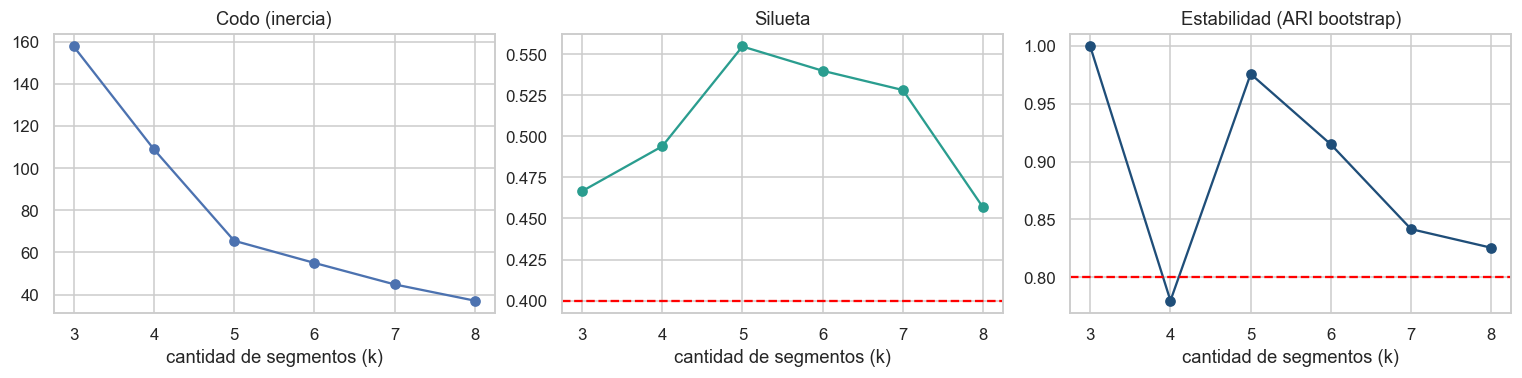

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
experimentos["inercia"].plot(marker="o", ax=ax[0], title="Codo (inercia)")
experimentos["silueta"].plot(marker="o", ax=ax[1], title="Silueta", color="#2a9d8f")
ax[1].axhline(config.CRITERIOS["silueta_min"], ls="--", color="red")
experimentos["estabilidad"].plot(marker="o", ax=ax[2], title="Estabilidad (ARI bootstrap)", color="#1f4e79")
ax[2].axhline(config.CRITERIOS["estabilidad_min"], ls="--", color="red")
for a in ax: a.set_xlabel("cantidad de segmentos (k)")
plt.tight_layout(); plt.savefig(FIG / "03_eleccion_k.png", bbox_inches="tight"); plt.show()

**Decisión de modelado:** k = 5. Es la mayor silueta (0,555), el codo de la inercia se marca ahí, es muy estable (0,97) y el segmento más chico tiene 11 % de los clientes. Además, cinco segmentos son manejables para Marketing (criterio de accionabilidad acordado en 2.1.1).

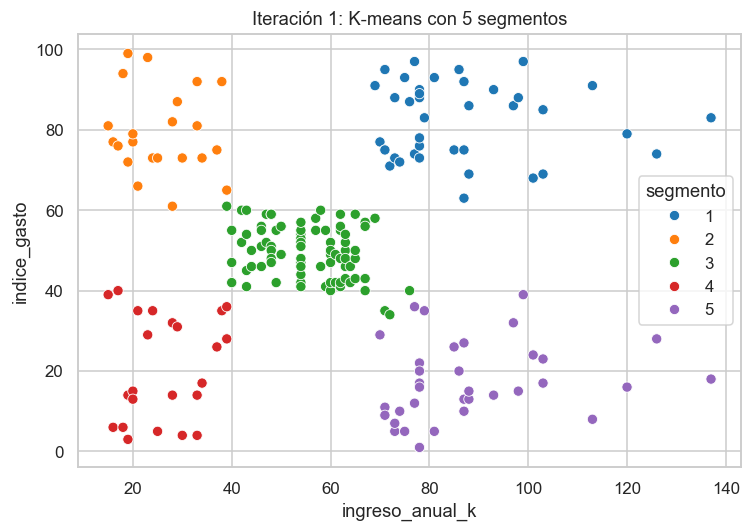

,ingreso_anual_k,indice_gasto,clientes
segmento,,,
1,86.5,82.1,39
2,25.7,79.4,22
3,55.3,49.5,81
4,26.3,20.9,23
5,88.2,17.1,35


In [4]:
km = modelado.kmeans(X, 5)
base["segmento"] = modelado.ordenar_etiquetas(km.labels_, base["indice_gasto"].values)
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=base, x="ingreso_anual_k", y="indice_gasto", hue="segmento", palette="tab10", s=45, ax=ax)
ax.set_title("Iteración 1: K-means con 5 segmentos")
plt.tight_layout(); plt.savefig(FIG / "03_segmentos_it1.png", bbox_inches="tight"); plt.show()
base.groupby("segmento")[["ingreso_anual_k", "indice_gasto"]].mean().round(1).assign(clientes=base["segmento"].value_counts())

## Evaluación de la iteración 1 (2.5.1)
Control técnico interno (no son requerimientos del cliente) más la revisión con Marketing contra los requerimientos de la versión 1.

In [5]:
r1 = evaluacion.evaluar(X, base["segmento"].values, base, 5)
chequeos = evaluacion.veredicto(r1)
pd.DataFrame({"resultado": [round(r1["silueta"], 3), round(r1["tamano_min_pct"], 1), round(r1["estabilidad"], 3)],
              "cumple": [chequeos["silueta >= 0,40"], chequeos["ningún segmento < 5 %"], chequeos["estabilidad >= 0,80"]]},
             index=["silueta", "segmento más chico (%)", "estabilidad"])

,resultado,cumple
silueta,0.555,True
segmento más chico (%),11.000,True
estabilidad,0.976,True


| Requerimiento de la versión 1 | Evidencia | Estado |
|---|---|---|
| RF.1 Cargar los datos | Resumen de carga: 200 de origen = 200 cargados + 0 rechazados; prueba automática con archivo alterado | Cumple |
| RF.2 Segmentar sin código | `python -m costanera.pipeline --segmentos 5` (Marketing eligió entre 3 y 8) | Cumple |
| RF.4 Tablero básico | Fuera del alcance por la solicitud de cambio CR-01 (aprobada el 30/10) | No aplica |

**Decisión firmada (06/11, H2):** se avanza a la iteración 2. Pendiente para la versión 2: fichas de perfil, composición por edad y género (equidad) y exportación.